# Studiul de caz 4 - Un indicator de risc pentru companiile energetice românești: stresul sistemic, riscul preț-volum și deficitul de producție din anii secetoși

Energy MBA - Analiza cantitativă a piețelor de energie (EMQA) - Prof. Daniel Traian Pele

Academia de Studii Economice din București - Academia Română, Institutul de Prognoză Economică

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.join("..", "common"))   # shared helpers: cases/common/case_utils.py
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import case_utils as cu
LANG = "ro"            # "en" or "ro": language of the charts shown below (both are saved)
cu.set_lang(LANG)
T = lambda en, ro: cu.T(LANG, en, ro)
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)
%matplotlib inline

**Lucrarea de referință.** Toma, F.-M., Dima, D.-M., Grecu, R., Pele, D. T. și Lessmann, S. (2026). Energy Financial Risk Meter: systemic risk in the EU energy
sector. SSRN, document de lucru 6985301. doi:10.2139/ssrn.6985301

**Conținutul notebook-ului.** (A) Construim o versiune românească, la scară redusă, a indicatorului Energy Financial Risk Meter (EFRM), pornind de la cele trei companii energetice listate la București
cu istoric lung (OMV Petrom, Romgaz, Nuclearelectrica): pentru fiecare companie, o regresie cuantilică LASSO a randamentelor, pentru cuantila de 5 % (zilele cu cele mai mari pierderi), în funcție de randamentele celorlalte companii și de prețurile
petrolului și gazelor; indicatorul este media penalizării alese pe baza datelor. (B) Verificăm dacă indicatorul semnalează din timp lunile cu volatilitate ridicată.
(C) Măsurăm două riscuri specifice companiilor energetice, care completează un indicator sistemic construit pe baza acțiunilor: riscul preț-volum al unui furnizor și deficitul de producție hidro
din anii secetoși pentru un producător care a vîndut la termen.

**Adaptarea pentru curs.** Lucrarea folosește 100 de companii energetice europene, factori macroeconomici europeni (TTF, Brent, indici STOXX, VSTOXX, stocuri de petrol) și
date LSEG, aprilie 2016 - aprilie 2026. Versiunea noastră compactă folosește 3 companii românești, Brent și Henry Hub ca factori, perioada 2016-2026 și o fereastră mobilă
de 250 de zile de tranzacționare (aleasă de noi).

## A. Un indicator de risc energetic românesc

In [2]:
eq = cu.equities_daily(); fu = cu.fuels_daily()
px = pd.concat({"SNP": eq["SNP_adjclose_ron"], "SNG": eq["SNG_adjclose_ron"], "SNN": eq["SNN_adjclose_ron"],
                "Brent": fu["brent_usd_bbl"] / fu["eurusd_ecb"], "HenryHub": fu["henryhub_usd_mmbtu"] / fu["eurusd_ecb"]}, axis=1)
vol = eq[["SNP_volume", "SNG_volume", "SNN_volume"]].sum(axis=1)
px = px[px.index.isin(vol[vol > 0].index)].dropna().loc["2015-04-01":]
X = np.log(px).diff().dropna()                       # daily log returns (decimals)
FIRMS, MACRO = ["SNP", "SNG", "SNN"], ["Brent", "HenryHub"]
print(X.shape, X.index.min().date(), X.index.max().date())

(2800, 5) 2015-04-02 2026-11-04


In [3]:
from sklearn.linear_model import QuantileRegressor
TAU, WIN, STEP = 0.05, 250, 5                         # 5 % quantile, 250-day window, re-estimated every 5 trading days
GRID = np.logspace(-6.5, -1.5, 21)                    # candidate penalties (sklearn units: penalty on the MEAN check loss)
def rho_tau(u, tau=TAU):
    return np.abs(u) * np.abs(tau - (u < 0))          # check function, c = 1
def lambda_gacv(y, Z):
    """Choose the LASSO penalty by GACV = sum rho_tau(residuals) / (n - df), df = number of non-zero coefficients (+ intercept)."""
    best = (np.inf, None)
    for lam in GRID:
        m = QuantileRegressor(quantile=TAU, alpha=lam, solver="highs").fit(Z, y)
        df = 1 + np.sum(np.abs(m.coef_) > 1e-8)
        g = rho_tau(y - m.predict(Z)).sum() / (len(y) - df)
        if g < best[0]:
            best = (g, lam)
    return best[1]
ends = range(WIN, len(X), STEP)
lam = {f: [] for f in FIRMS}
for e in ends:
    w = X.iloc[e - WIN:e]
    Zs = (w - w.mean()) / w.std()                     # standardise covariates within the window
    for f in FIRMS:
        cov = [c for c in FIRMS if c != f] + MACRO
        lam[f].append(lambda_gacv(w[f].values, Zs[cov].values))
lam = pd.DataFrame(lam, index=X.index[[e - 1 for e in ends]])
erm = lam.mean(axis=1).rename("RO-ERM")              # risk meter = average penalty across firms (paper: EFRM_t = (1/J) sum_j lambda_j,t)
print(erm.describe().round(6))
print("share of firm-windows at the lowest / highest grid value: %.1f %% / %.1f %%" % (100 * (lam == GRID[0]).values.mean(), 100 * (lam == GRID[-1]).values.mean()))

count    510.000000
mean       0.001640
std        0.001732
min        0.000000
25%        0.000140
50%        0.001054
75%        0.002467
max        0.007721
Name: RO-ERM, dtype: float64
share of firm-windows at the lowest / highest grid value: 53.9 % / 0.0 %


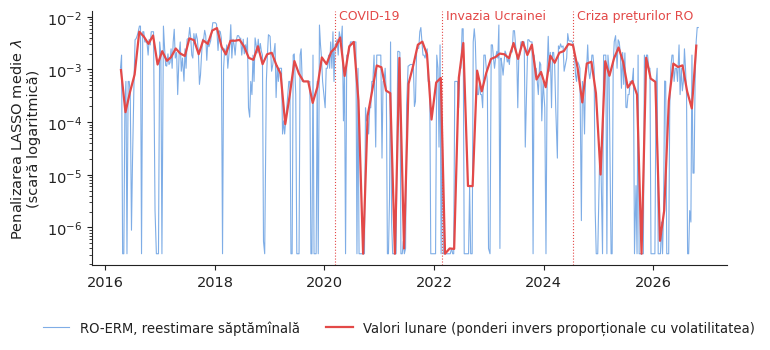

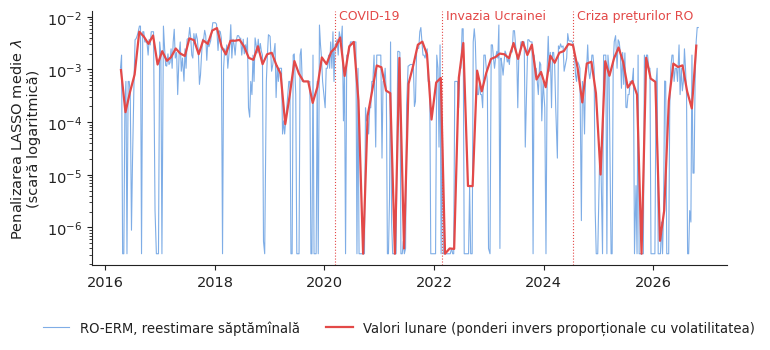

In [4]:
# monthly aggregation with inverse-volatility weights (paper, Sec. 3.1.2): V_m = sum(EFRM_t / sigma_t) / sum(1 / sigma_t), sigma_t = 5-observation rolling s.d.
sig = erm.rolling(5).std().replace(0, np.nan)          # no back-filling: windows without a volatility estimate get no weight
erm_m = ((erm / sig).resample("MS").sum(min_count=1) / (1 / sig).resample("MS").sum(min_count=1)).fillna(erm.resample("MS").mean())   # month without any sigma: simple mean
EVENTS = [("2020-03-09", ("COVID-19", "COVID-19")), ("2022-02-24", ("Invasion of Ukraine", "Invazia Ucrainei")),
          ("2024-07-15", ("RO price crisis", "Criza prețurilor RO"))]
def fig_erm(lang):
    fig, ax = plt.subplots(figsize=(8.2, 3.3))
    ax.plot(erm.index, erm, color=cu.PAL["RO"], lw=0.8, alpha=0.6, label=cu.T(lang, "RO-ERM, weekly re-estimation", "RO-ERM, reestimare săptămînală"))
    ax.plot(erm_m.index + pd.Timedelta(days=14), erm_m, color=cu.PAL["c8"], lw=1.6, label=cu.T(lang, "Monthly (inverse-volatility weights)", "Valori lunare (ponderi invers proporționale cu volatilitatea)"))
    for d, l in EVENTS:
        ax.axvline(pd.Timestamp(d), color=cu.EVENT, lw=0.8, ls=":")
        ax.text(pd.Timestamp(d), ax.get_ylim()[1] if False else erm.max() * 1.02, " " + cu.T(lang, *l), color=cu.EVENT, fontsize=9, va="bottom")
    ax.set_yscale("log")
    ax.set_ylabel(cu.T(lang, "Average LASSO penalty $\\lambda$\n(log scale)", "Penalizarea LASSO medie $\\lambda$\n(scară logaritmică)"))
    cu.legend_bottom(fig, ncol=2)
    return fig
cu.save_both(fig_erm, "f1_risk_meter", headline=True)

**Interpretarea lui λ.** Pentru fiecare companie, regresia modelează cuantila de 5 % a randamentelor (zilele cu cele mai mari pierderi) în funcție de randamentele celorlalte companii și de prețurile petrolului și gazelor.
Penalizarea λ este aleasă pe baza datelor: cînd mișcarea comună din coada distribuției este puternică și zgomotoasă, este nevoie de o penalizare mai mare pentru ca modelul să nu fie supraajustat.
Lucrarea interpretează un λ mai mare drept „expunere mai mare la riscul sistemic” (secțiunea 3.1.1) și calculează media valorilor λ pe companii pentru a obține indicele.

## B. Semnalează indicatorul din timp lunile cu volatilitate ridicată?

In [5]:
from scipy.stats import norm
from sklearn.metrics import roc_auc_score
import statsmodels.api as sm
basket = X[FIRMS].mean(axis=1)
rv = basket.groupby(pd.Grouper(freq="MS")).std() * np.sqrt(252) * 100           # monthly realised volatility of the basket, % p.a.
dfm = pd.DataFrame({"rv": rv, "erm": erm_m}).dropna()
dfm["d_erm"] = dfm.erm.diff()
# event in month m+1: volatility above the expanding 75th percentile known at month m (paper, exercise 2)
dfm["thr"] = dfm.rv.expanding(12).quantile(0.75)
dfm["event_next"] = (dfm.rv.shift(-1) > dfm.thr).astype(float)
dfm.loc[dfm.index[-1], "event_next"] = np.nan
dfm = dfm.dropna()
T0 = 36                                                                         # expanding window, first 36 months for estimation (paper: 60 of 113)
preds = {"RO-ERM": [], "Past volatility": [], "RO-ERM + past volatility": []}
spec = {"RO-ERM": ["erm"], "Past volatility": ["rv"], "RO-ERM + past volatility": ["erm", "rv"]}
yy = []
for t in range(T0, len(dfm)):
    tr = dfm.iloc[:t]; te = dfm.iloc[t:t + 1]
    yy.append(te.event_next.values[0])
    for k, cols in spec.items():
        Z = sm.add_constant((tr[cols] - tr[cols].mean()) / tr[cols].std())
        try:
            m = sm.Probit(tr.event_next, Z).fit(disp=False)
            zt = sm.add_constant((te[cols] - tr[cols].mean()) / tr[cols].std(), has_constant="add")
            preds[k].append(float(m.predict(zt)[0]))
        except Exception:
            preds[k].append(tr.event_next.mean())
yy = np.array(yy)
auc = pd.Series({k: roc_auc_score(yy, v) for k, v in preds.items()})
bss = pd.Series({k: 1 - np.mean((np.array(v) - yy) ** 2) / np.mean((yy.mean() - yy) ** 2) for k, v in preds.items()})
ew = pd.DataFrame({"AUC": auc, "BSS": bss})
print("out-of-sample months:", len(yy), "events:", int(yy.sum()))
cu.show_table(ew, best={"AUC": "max", "BSS": "max"}, digits=3)

out-of-sample months: 79 events: 26


,AUC,BSS
RO-ERM,0.382,-0.029
Past volatility,0.612,0.003
RO-ERM + past volatility,0.593,-0.012


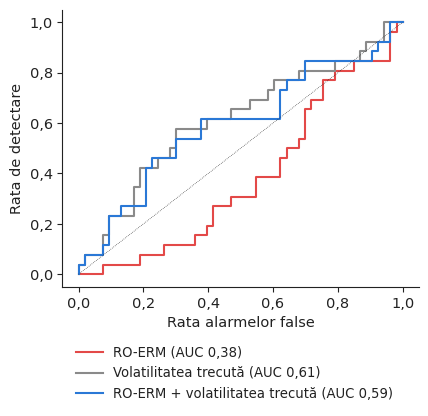

In [6]:
from sklearn.metrics import roc_curve
def fig_roc(lang):
    fig, ax = plt.subplots(figsize=(4.6, 3.6))
    cols = {"RO-ERM": cu.PAL["c8"], "Past volatility": cu.MUTED, "RO-ERM + past volatility": cu.PAL["RO"]}
    labs = {"RO-ERM": ("RO-ERM", "RO-ERM"), "Past volatility": ("Past volatility", "Volatilitatea trecută"),
            "RO-ERM + past volatility": ("RO-ERM + past volatility", "RO-ERM + volatilitatea trecută")}
    for k, v in preds.items():
        f, tpr, _ = roc_curve(yy, v)
        ax.plot(f, tpr, color=cols[k], lw=1.5, label=f"{cu.T(lang, *labs[k])} (AUC {cu.fmt(auc[k], 2, lang)})")
    ax.plot([0, 1], [0, 1], color=cu.INK, lw=0.5, ls=":")
    ax.set_xlabel(cu.T(lang, "False alarm rate", "Rata alarmelor false")); ax.set_ylabel(cu.T(lang, "Hit rate", "Rata de detectare"))
    cu.comma_axis(ax, lang, "x", 1); cu.comma_axis(ax, lang, "y", 1)
    cu.legend_bottom(fig, ncol=1)
    return fig
cu.save_both(fig_roc, "f2_early_warning")
names_ew = {"RO-ERM": ("RO-ERM alone", "RO-ERM singur"), "Past volatility": ("Past volatility alone", "Volatilitatea trecută singură"),
            "RO-ERM + past volatility": ("RO-ERM + past volatility", "RO-ERM + volatilitatea trecută")}
t = ew.copy(); t.index = [names_ew[i] for i in t.index]
cu.write_table(t, "early_warning", header=[("Predictor of a turbulent next month", "Variabila de avertizare pentru luna următoare"), ("AUC", "AUC"), ("Brier skill score", "Scorul Brier relativ")],
               digits=3, best={"AUC": "max", "BSS": "max"})

## C1. Un risc specific sectorului energetic: riscul preț-volum (furnizorul care alimentează consumatori finali)

daily price-load correlation: -0.017
                 base  shaped  premium_pct  premium_eur
timestamp_utc                                          
2016            33.12   34.10         3.01         0.98
2017            48.06   50.03         4.04         1.97
2018            46.37   48.01         3.69         1.64
2019            50.36   52.12         3.51         1.76
2020            39.47   40.83         3.29         1.36
2021           110.99  114.75         3.05         3.75
2022           264.54  272.90         3.32         8.36
2023           103.98  108.10         4.01         4.12
2024           103.38  109.43         5.62         6.04
2025           108.45  113.83         5.21         5.38
2026           137.01  144.95         6.10         7.94


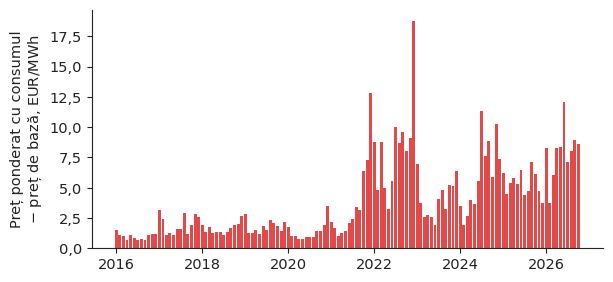

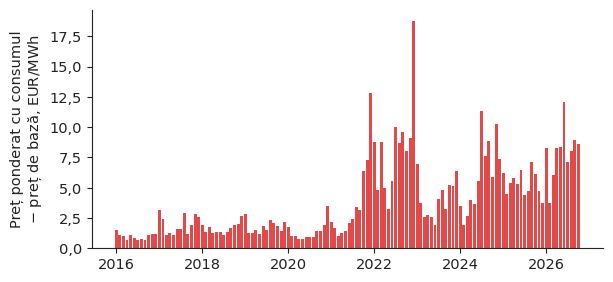

In [7]:
p = cu.prices_hourly()["RO"]; L = cu.generation_ro_hourly()["load"]
h = pd.concat({"p": p, "L": L}, axis=1).dropna().loc["2016-01-01":"2026-10-31"]
mon = h.groupby(pd.Grouper(freq="MS")).apply(lambda d: pd.Series({"base": d.p.mean(), "shaped": (d.p * d.L).sum() / d.L.sum()}))
mon["premium_pct"] = 100 * (mon.shaped / mon.base - 1)
mon["premium_eur"] = mon.shaped - mon.base
ann = mon.groupby(mon.index.year).mean()
corr_daily = h.resample("D").mean().corr().loc["p", "L"]
print("daily price-load correlation: %.3f" % corr_daily)
print(ann.round(2))
def fig_pv(lang):
    fig, ax = plt.subplots(figsize=(6.6, 3.1))
    ax.bar(mon.index, mon.premium_eur, width=25, color=np.where(mon.premium_eur > 0, cu.PAL["c8"], cu.PAL["HU"]))
    ax.axhline(0, color=cu.INK, lw=0.5)
    ax.set_ylabel(cu.T(lang, "Load-weighted $-$ base\nprice, EUR/MWh", "Preț ponderat cu consumul\n$-$ preț de bază, EUR/MWh"))
    cu.comma_axis(ax, lang, "y")
    return fig
cu.save_both(fig_pv, "f3_price_volume")

**Interpretarea graficului.** Un furnizor care cumpără energie în bandă (*baseload*), dar trebuie să livreze conform profilului consumatorilor casnici, cumpără mai mult în orele scumpe:
prețul *ponderat cu consumul* depășește prețul *de bază*. Acest cost de profil a crescut puternic în 2022 și este determinat acum de vîrfurile de seară și de orele de prînz cu producție solară mare.

## C2. Un risc specific sectorului energetic: deficitul de producție din anii secetoși (producătorul hidro care a vîndut la termen)

      hydro_TWh   price  shortfall_TWh  buyback_mEUR
2016      18.14   33.16           0.00          0.00
2017      14.59   48.08           0.95         45.80
2018      17.72   46.41           0.00          0.00
2019      15.71   50.41           0.00          0.00
2020      15.37   39.49           0.17          6.69
2021      17.42  111.41           0.00          0.00
2022      14.05  265.30           1.49        393.99
2023      18.35  103.74           0.00          0.00
2024      14.21  103.51           1.33        137.31
2025      12.15  108.16           3.39        366.53
P50 = 15.54 TWh; correlation hydro output - price: -0.36


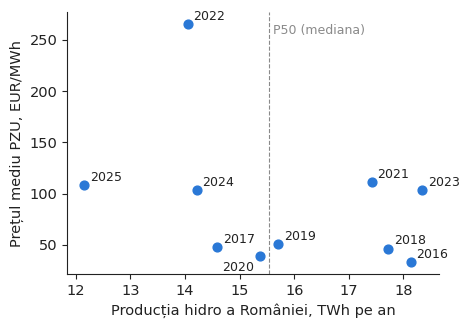

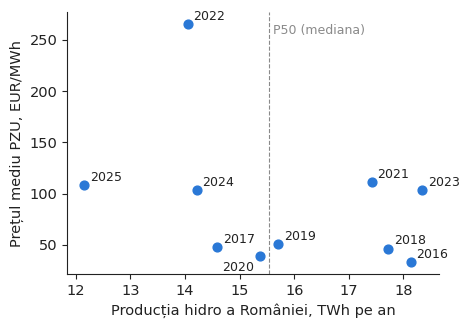

In [8]:
gd = cu.generation_ro_daily(); pdly = cu.prices_daily()["RO"]
hyd = (gd.hydro_water_reservoir + gd.hydro_run_of_river)
yrs = range(2016, 2026)
H = pd.DataFrame({"hydro_TWh": [hyd.loc[str(y)].mean() * 8.76 / 1000 for y in yrs],            # mean MW x 8760 h -> TWh
                  "price": [pdly.loc[str(y)].mean() for y in yrs]}, index=list(yrs))
P50 = H.hydro_TWh.median()
H["shortfall_TWh"] = (P50 - H.hydro_TWh).clip(lower=0)
H["buyback_mEUR"] = H.shortfall_TWh * 1e6 * H.price / 1e6                                       # buy the missing volume at the year's average spot price
corr_hp = H.hydro_TWh.corr(H.price)
print(H.round(2)); print("P50 = %.2f TWh; correlation hydro output - price: %.2f" % (P50, corr_hp))
cu.write_table(H.rename(index=str), "hydro", header=[("Year", "Anul"), ("Hydro output, TWh", "Producția hidro, TWh"), ("Spot price, EUR/MWh", "Prețul spot, EUR/MWh"),
               ("Shortfall vs P50, TWh", "Deficit față de P50, TWh"), ("Buy-back cost, mil. EUR", "Costul recumpărării, mil. EUR")],
               digits={"hydro_TWh": 2, "price": 1, "shortfall_TWh": 2, "buyback_mEUR": 0}, best={"buyback_mEUR": "max"})
def fig_hydro(lang):
    fig, ax = plt.subplots(figsize=(4.8, 3.4))
    ax.scatter(H.hydro_TWh, H.price, s=40, color=cu.PAL["RO"], zorder=3)
    for y_, r_ in H.iterrows():
        ax.annotate(str(y_), (r_.hydro_TWh, r_.price), textcoords="offset points", fontsize=9,
                    xytext=(-4, -4) if y_ == 2020 else (4, 3), ha="right" if y_ == 2020 else "left", va="top" if y_ == 2020 else "baseline")
    ax.axvline(P50, color=cu.MUTED, ls="--", lw=0.8)
    ax.text(P50, H.price.max(), cu.T(lang, " P50 (median)", " P50 (mediana)"), color=cu.MUTED, fontsize=9, va="top")
    ax.set_xlabel(cu.T(lang, "Romanian hydro output, TWh per year", "Producția hidro a României, TWh pe an"))
    ax.set_ylabel(cu.T(lang, "Average day-ahead price, EUR/MWh", "Prețul mediu PZU, EUR/MWh"))
    cu.comma_axis(ax, lang, "x", 1)
    return fig
cu.save_both(fig_hydro, "f4_dry_year")

In [9]:
pk = erm.idxmax()
cu.write_numbers({
    "start": (f"{erm.index.min():%B %Y}", f"{erm.index.min():%m.%Y}"), "end": (f"{erm.index.max():%B %Y}", f"{erm.index.max():%m.%Y}"),
    "nObs": len(X), "nWin": len(erm), "lamFloor": 100 * (lam == GRID[0]).values.mean(), "ermPeak": (f"{pk:%B %Y}", f"{pk:%m.%Y}"),
    "ermPre": erm.loc["2018":"2019"].mean() * 1e3, "ermCovid": erm.loc["2020-03":"2020-06"].mean() * 1e3, "ermWar": erm.loc["2022-03":"2022-12"].mean() * 1e3,
    "ermLast": erm.loc["2025-11":].mean() * 1e3,
    "nOOS": len(yy), "nEvents": int(yy.sum()), "aucERM": auc["RO-ERM"], "aucVol": auc["Past volatility"], "aucBoth": auc["RO-ERM + past volatility"],
    "bssERM": bss["RO-ERM"], "bssBoth": bss["RO-ERM + past volatility"],
    "corrPL": corr_daily, "premTwoTwo": ann.loc[2022, "premium_eur"], "premPctTwoTwo": ann.loc[2022, "premium_pct"],
    "premLast": ann.loc[2025, "premium_eur"], "premPctLast": ann.loc[2025, "premium_pct"], "premEarly": ann.loc[2016:2019, "premium_pct"].mean(),
    "Pfifty": P50, "corrHP": corr_hp, "shortTwoTwo": H.loc[2022, "shortfall_TWh"], "buyTwoTwo": H.loc[2022, "buyback_mEUR"],
    "hydTwoTwo": H.loc[2022, "hydro_TWh"], "priceTwoTwo": H.loc[2022, "price"], "shortTwoFive": H.loc[2025, "shortfall_TWh"],
    "buyTwoFive": H.loc[2025, "buyback_mEUR"], "maxBuy": H.buyback_mEUR.max(), "maxBuyYear": int(H.buyback_mEUR.idxmax()),
}, digits={"lamFloor": 0, "ermPre": 3, "ermCovid": 3, "ermWar": 3, "ermLast": 3, "aucERM": 3, "aucVol": 3, "aucBoth": 3, "bssERM": 3, "bssBoth": 3,
           "corrPL": 2, "premTwoTwo": 1, "premPctTwoTwo": 1, "premLast": 1, "premPctLast": 1, "premEarly": 1, "Pfifty": 2, "corrHP": 2,
           "shortTwoTwo": 2, "buyTwoTwo": 0, "hydTwoTwo": 2, "priceTwoTwo": 1, "shortTwoFive": 2, "buyTwoFive": 0, "maxBuy": 0})

In [10]:
# slide-ready summary for the lecture box "Research from our group" (max 6 lines), both languages; every number comes from this notebook
for lang in ("en", "ro"):
    F = lambda v, nd=2: cu.fmt(float(v), nd, lang).replace("-", "$-$")
    t = lambda en, ro: ro if lang == "ro" else en
    lines = [
        t("\\textbf{Energy Financial Risk Meter} (Toma, Dima, Grecu, Pele \\& Lessmann, 2026, SSRN): LASSO quantile network of 100 EU energy firms; captures COVID and the 2022 war; with CISS predicts volatile months (AUC 0.731, Section~4.8.3).",
          "\\textbf{Energy Financial Risk Meter} (Toma, Dima, Grecu, Pele și Lessmann, 2026, SSRN): o rețea de regresii cuantilice LASSO pentru 100 de companii energetice din UE; surprinde pandemia de COVID-19 și războiul din 2022; împreună cu CISS, prognozează lunile cu volatilitate ridicată (AUC 0,731, secțiunea~4.8.3)."),
        t(f"Our 3-firm Romanian version reaches AUC {F(auc['RO-ERM'])} ({len(yy)} out-of-sample months): breadth of the cross-section matters --- a systemic meter needs many firms.",
          f"Versiunea noastră românească, cu 3 companii, obține un AUC de {F(auc['RO-ERM'])} ({len(yy)} de luni în afara eșantionului de estimare): dimensiunea eșantionului contează --- un indicator sistemic are nevoie de multe companii."),
        t(f"Energy-specific risks to track alongside a systemic meter: price--volume premium {F(ann.loc[2025, 'premium_pct'], 1)}\\,\\% of the base price in 2025; dry-year buy-back up to {F(H.buyback_mEUR.max(), 0)} mil.\\ EUR ({int(H.buyback_mEUR.idxmax())}) for P50 hydro sold forward.",
          f"Riscuri specifice sectorului energetic, de urmărit alături de un indicator sistemic: o primă preț--volum de {F(ann.loc[2025, 'premium_pct'], 1)}\\,\\% din prețul de bază în 2025; un cost de recumpărare în anii secetoși de pînă la {F(H.buyback_mEUR.max(), 0)} mil.\\ EUR ({int(H.buyback_mEUR.idxmax())}) pentru producția hidro P50 vîndută la termen."),
    ]
    with open(f"slide_summary_{lang}.tex", "w", encoding="utf-8") as fh:
        fh.write("% slide-ready summary for the lecture box 'Research from our group' (max 6 lines); generated by the notebook\n\\begin{itemize}\\setlength{\\itemsep}{2pt}\n")
        for l_ in lines:
            fh.write("  \\item " + l_ + "\n")
        fh.write("\\end{itemize}\n")
print(open("slide_summary_en.tex", encoding="utf-8").read())

% slide-ready summary for the lecture box 'Research from our group' (max 6 lines); generated by the notebook
\begin{itemize}\setlength{\itemsep}{2pt}
  \item \textbf{Energy Financial Risk Meter} (Toma, Dima, Grecu, Pele \& Lessmann, 2026, SSRN): LASSO quantile network of 100 EU energy firms; captures COVID and the 2022 war; with CISS predicts volatile months (AUC 0.731, Section~4.8.3).
  \item Our 3-firm Romanian version reaches AUC 0.38 (79 out-of-sample months): breadth of the cross-section matters --- a systemic meter needs many firms.
  \item Energy-specific risks to track alongside a systemic meter: price--volume premium 5.2\,\% of the base price in 2025; dry-year buy-back up to 394 mil.\ EUR (2022) for P50 hydro sold forward.
\end{itemize}



## Exerciții suplimentare
1. Adăugați Hidroelectrica (H2O), din iulie 2023, și recalculați indicatorul pe eșantionul mai scurt. Schimbă a patra companie concluziile?
2. Înlocuiți fereastra de 250 de zile cu ferestre de 125 și de 500 de zile. Care alegere oferă cel mai devreme semnalul dinaintea lunii martie 2020?
3. Pentru producătorul hidro: ce parte din producția așteptată (P50, P75, P90) ați vinde la termen, ținînd seama de costurile de recumpărare din tabel?